# Лабораторная работа № 3. Современные свёрточные архитектуры: ResNet и SE-блоки

**Тема:** глубокие свёрточные нейронные сети, остаточные связи и адаптивное перевзвешивание признаков.

**Цель:** изучить основные принципы построения глубоких CNN, понять назначение residual connections и познакомиться с идеей внимания к признакам на примере SE-блоков.

В этой работе мы перейдём от простых свёрточных сетей к более глубоким архитектурам. Сначала разберём трудности оптимизации глубоких сетей и идею остаточного обучения, затем рассмотрим механизм Squeeze-and-Excitation. После этого построим классификаторы для CIFAR-10, сравним базовую CNN, ResNet и ResNet с SE-блоками, а также проанализируем влияние глубины и перевзвешивания каналов.

In [ ]:
# Проверяем версии библиотек и выбираем устройство, на котором будут выполняться вычисления.
import sys
import platform
import torch

# Сначала фиксируем версии среды: это помогает понять, какие возможности PyTorch и CUDA доступны.
print(f"Python: {sys.version.split()[0]}")
print(f"Платформа: {platform.platform()}")
print(f"PyTorch: {torch.__version__}")
print(f"CUDA доступна: {torch.cuda.is_available()}")
print(f"CUDA-сборка PyTorch: {torch.version.cuda}")

# Выбираем единое устройство для дальнейших вычислений; при отсутствии CUDA используем CPU.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Устройство для вычислений: {device}")

# Дополнительные сведения о видеокарте выводим только тогда, когда CUDA действительно доступна.
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"CUDA-устройств: {torch.cuda.device_count()}")

## Что было рассмотрено в лабораторной работе № 2

В предыдущей работе мы строили свёрточную сеть для классификации Fashion-MNIST. В ней использовались свёрточные блоки, Batch Normalization и pooling. Мы также сравнивали обычный Dropout и Dropout2d и наблюдали, как регуляризация влияет на разницу между обучающим и валидационным качеством.

Такая сеть состояла из небольшого числа свёрточных слоёв. Увеличим глубину модели и посмотрим, почему простое добавление новых слоёв не всегда улучшает результат.

## Увеличение глубины нейросетей и проблемы оптимизации

Глубина CNN - число последовательных преобразований, через которые проходит входной сигнал. При увеличении глубины сеть потенциально может строить более сложные иерархии признаков:

- ранние слои реагируют на простые локальные структуры: границы, цветовые переходы и текстуры;
- промежуточные слои объединяют их в более сложные фрагменты;
- глубокие слои формируют признаки, полезные для распознавания объектов целиком.

Однако более глубокая сеть не обязательно обучается лучше. При обучении градиент функции потерь распространяется от выходных слоёв к ранним. На каждом слое он преобразуется с помощью производных соответствующих операций.

Если нормы градиентов при движении к началу сети систематически уменьшаются, возникает **затухание градиента**. Ранние слои получают очень маленькие обновления и могут обучаться медленно.

Возможна и обратная проблема - **взрыв градиента**, когда нормы градиентов становятся чрезмерно большими. Это может приводить к нестабильным обновлениям параметров.

Есть и другая трудность - **деградация качества глубоких сетей**. В некоторых условиях более глубокая обычная сеть показывает большую ошибку даже на обучающей выборке, чем более мелкая. Это не то же самое, что переобучение: проблема может возникнуть уже при оптимизации обучающей ошибки.

Один из способов облегчить обучение глубоких CNN - использовать остаточные связи.


## Градиенты в глубокой сети

Для последовательности преобразований градиент передаётся по правилу цепочки:

$$
\frac{\partial \mathcal{L}}{\partial \mathbf{x}_0}
=
\frac{\partial \mathcal{L}}{\partial \mathbf{x}_n}
\prod_{i=1}^{n}
\frac{\partial \mathbf{x}_i}{\partial \mathbf{x}_{i-1}}.
$$

Если нормы множителей в среднем меньше единицы, градиент может уменьшаться по мере прохождения к началу сети. Если они существенно больше единицы, градиент может расти.

Для диагностики удобно измерять норму градиентов параметров отдельных слоёв:

$$
\|\nabla W_l\|_2 =
\sqrt{\sum_j \left(\frac{\partial \mathcal{L}}{\partial W_{l,j}}\right)^2}.
$$

Норма градиента не является метрикой качества. Она помогает увидеть, получают ли разные части сети сигнал для обновления параметров.

### Визуализация нормы градиента на разной глубине

Для наглядности сравним распространение градиента в двух сетях одинаковой ширины:

- обычная глубокая сеть последовательно применяет свёрточные слои;
- остаточная сеть содержит блоки с коротким путём, обходящим преобразования блока.

Вычислим норму градиента по выходным тензорам отдельных блоков после одного обратного прохода. Это демонстрационный снимок для одной инициализации и одного батча: он помогает увидеть механизм, но сам по себе не доказывает, что одна архитектура всегда будет иметь большие градиенты.

In [2]:
# Определяем две небольшие глубокие сети, сохраняющие промежуточные активации для анализа градиентов.
import torch.nn as nn


class PlainDeepCNN(nn.Module):
    """Последовательная сеть без остаточных связей для демонстрации градиентов."""

    def __init__(
        self, channels: int = 32, depth: int = 8, num_classes: int = 10
    ) -> None:
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(channels),
            nn.ReLU(),
        )
        self.layers = nn.ModuleList(
            [
                nn.Sequential(
                    nn.Conv2d(channels, channels, kernel_size=3, padding=1, bias=False),
                    nn.BatchNorm2d(channels),
                    nn.ReLU(),
                )
                for _ in range(depth)
            ]
        )
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Linear(channels, num_classes)

    def forward_with_activations(self, x: torch.Tensor):
        """Возвращает логиты и выходы последовательных слоёв."""
        activations = []
        x = self.stem(x)
        x.retain_grad()
        activations.append(x)
        for layer in self.layers:
            x = layer(x)
            x.retain_grad()
            activations.append(x)
        logits = self.classifier(self.pool(x).flatten(1))
        return logits, activations


class GradientResidualBlock(nn.Module):
    """Остаточный блок одинаковой размерности для демонстрации градиентов."""

    def __init__(self, channels: int = 32) -> None:
        super().__init__()
        self.branch = nn.Sequential(
            nn.Conv2d(channels, channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(channels),
            nn.ReLU(),
            nn.Conv2d(channels, channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(channels),
        )
        self.activation = nn.ReLU()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.activation(x + self.branch(x))


class ResidualDeepCNN(nn.Module):
    """Глубокая сеть с последовательностью остаточных блоков."""

    def __init__(
        self, channels: int = 32, depth: int = 8, num_classes: int = 10
    ) -> None:
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(channels),
            nn.ReLU(),
        )
        self.blocks = nn.ModuleList(
            [GradientResidualBlock(channels) for _ in range(depth)]
        )
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Linear(channels, num_classes)

    def forward_with_activations(self, x: torch.Tensor):
        """Возвращает логиты и выходы остаточных блоков."""
        activations = []
        x = self.stem(x)
        x.retain_grad()
        activations.append(x)
        for block in self.blocks:
            x = block(x)
            x.retain_grad()
            activations.append(x)
        logits = self.classifier(self.pool(x).flatten(1))
        return logits, activations

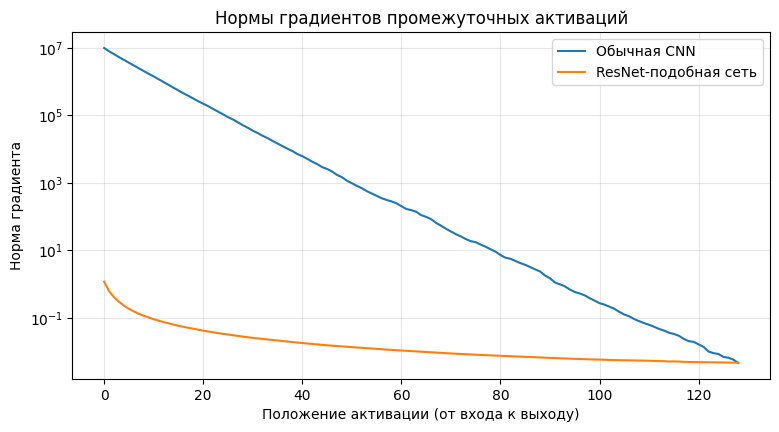

In [3]:
# Сравниваем нормы градиентов промежуточных активаций после одного backward().
import matplotlib.pyplot as plt
import numpy as np

torch.manual_seed(42)

gradient_batch = torch.randn(16, 3, 32, 32, device=device)
gradient_targets = torch.randint(0, 10, (16,), device=device)
gradient_criterion = nn.CrossEntropyLoss()

gradient_models = {
    "Обычная CNN": PlainDeepCNN(depth=128).to(device),
    "ResNet-подобная сеть": ResidualDeepCNN(depth=128).to(device),
}

gradient_norms = {}

for model_name, model in gradient_models.items():
    model.train()
    model.zero_grad(set_to_none=True)
    logits, activations = model.forward_with_activations(gradient_batch)
    loss = gradient_criterion(logits, gradient_targets)
    loss.backward()

    gradient_norms[model_name] = [
        activation.grad.norm().item() for activation in activations
    ]

depth_positions = np.arange(len(next(iter(gradient_norms.values()))))

plt.figure(figsize=(9, 4.5))

for model_name, norms in gradient_norms.items():
    plt.plot(depth_positions, norms, label=model_name)

plt.xlabel("Положение активации (от входа к выходу)")
plt.ylabel("Норма градиента")
plt.title("Нормы градиентов промежуточных активаций")
plt.yscale("log")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

**Небольшое исследование.** Сравните кривые на графике. Насколько сильно меняется норма градиента от ранних слоёв к поздним? Повторите эксперимент с другим seed или глубиной сети. Почему одного обратного прохода недостаточно, чтобы сделать универсальный вывод о поведении архитектуры?


## Остаточное обучение и residual connections

**Остаточная связь** (*residual connection*, или shortcut connection) добавляет к результату преобразования исходный вход блока. Вместо того чтобы обучать блок напрямую отображать вход $x$ в желаемый результат $H(x)$, сеть учится вычислять остаток $F(x)$:

$$
H(x)=F(x)+x.
$$

Здесь $F(x)$ - результат нескольких слоёв внутри блока, а $x$ - вход, передаваемый по короткому пути.

Если оптимальное преобразование близко к тождественному, блоку достаточно научиться выдавать небольшой остаток. Кроме того, при обратном распространении градиента появляется путь через сложение, который не проходит через все преобразования внутри ветви.

Для блока с изменением размерности вход нельзя напрямую сложить с результатом свёрток. В этом случае используют проекцию - обычно свёртку $1 \times 1$ с нужным числом выходных каналов и шагом.


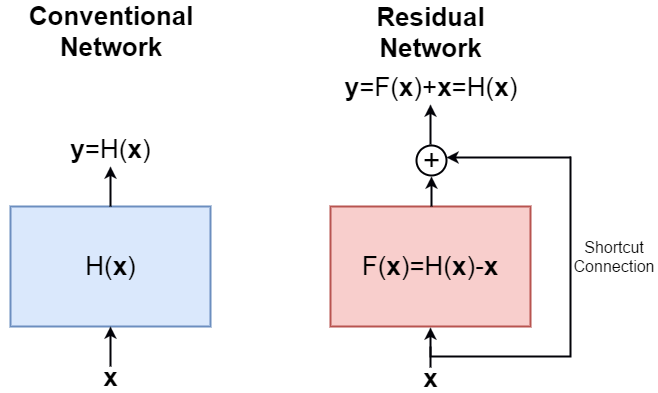

### Структура residual-блока

В простом residual-блоке используются две свёртки:

1. `Conv2d` → `BatchNorm2d` → `ReLU`;
2. `Conv2d` → `BatchNorm2d`;
3. `Dropout2d` (опционально);
4. сложение результата с shortcut;
5. `ReLU` после сложения.

Если число каналов и пространственные размеры не меняются, shortcut - тождественное отображение. Если меняются, shortcut содержит проекцию.

Схематически:

$$
y=\operatorname{ReLU}(F(x)+S(x)),
$$

где $S(x)=x$ для тождественного shortcut или $S(x)=W_s \odot x$ для проекции.

In [4]:
# Реализуем residual-блок с поддержкой изменения числа каналов и пространственного разрешения.
class BasicBlock(nn.Module):
    """Двухслойный residual-блок для небольших изображений CIFAR-10."""

    expansion = 1

    def __init__(
        self,
        in_channels: int,
        out_channels: int,
        stride: int = 1,
    ) -> None:
        super().__init__()

        self.conv1 = nn.Conv2d(
            in_channels,
            out_channels,
            kernel_size=3,
            stride=stride,
            padding=1,
            bias=False,
        )
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv2d(
            out_channels,
            out_channels,
            kernel_size=3,
            stride=1,
            padding=1,
            bias=False,
        )
        self.bn2 = nn.BatchNorm2d(out_channels)

        self.dropout = nn.Dropout2d(p=0.1)

        # Проекция нужна, если shortcut должен изменить размерность входного тензора.
        if stride != 1 or in_channels != out_channels * self.expansion:
            self.shortcut = nn.Sequential(
                nn.Conv2d(
                    in_channels,
                    out_channels * self.expansion,
                    kernel_size=1,
                    stride=stride,
                    bias=False,
                ),
                nn.BatchNorm2d(out_channels * self.expansion),
            )
        else:
            self.shortcut = nn.Identity()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Вычисляет F(x) + S(x) и применяет нелинейность."""
        identity = self.shortcut(x)

        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)

        out = self.dropout(out)

        out += identity
        return self.relu(out)

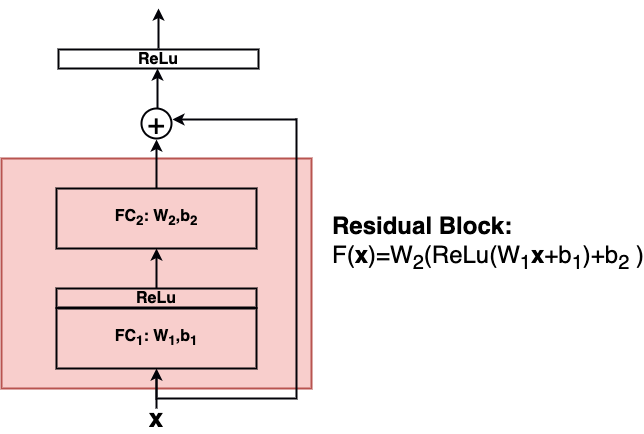

In [5]:
# Проверяем residual-блок как при сохранении размерности, так и при её изменении.
same_shape_block = BasicBlock(in_channels=32, out_channels=32, stride=1)
downsample_block = BasicBlock(in_channels=32, out_channels=64, stride=2)

sample_features = torch.randn(4, 32, 32, 32)

same_shape_output = same_shape_block(sample_features)
downsample_output = downsample_block(sample_features)

print("Вход:", tuple(sample_features.shape))
print("Выход блока без изменения размерности:", tuple(same_shape_output.shape))
print("Выход блока с проекцией:", tuple(downsample_output.shape))

Вход: (4, 32, 32, 32)
Выход блока без изменения размерности: (4, 32, 32, 32)
Выход блока с проекцией: (4, 64, 16, 16)


**Небольшое задание.** Объясните, почему в `BasicBlock` для проекции используется ядро $1 \times 1$. Что произойдёт, если попытаться сложить тензоры с формами `(B, 32, 32, 32)` и `(B, 64, 16, 16)` без изменения shortcut?


In [ ]:
%pip install aggdraw git+https://github.com/atrepalin/visualtorch -qU --no-deps

In [6]:
from collections import defaultdict
import visualtorch


class Multiply(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, x: torch.Tensor, y: torch.Tensor) -> torch.Tensor:
        return x * y


color_map = defaultdict(dict)


color_map[visualtorch.Input]["fill"] = "#E69F00"  # Orange
color_map[nn.Identity]["fill"] = "#56B4E9"  # Sky Blue
color_map[nn.Conv2d]["fill"] = "#009E73"  # Bluish Green
color_map[nn.BatchNorm2d]["fill"] = "#F0E442"  # Yellow
color_map[nn.ReLU]["fill"] = "#0072B2"  # Blue
color_map[nn.Linear]["fill"] = "#E15759"  # Coral
color_map[nn.MaxPool2d]["fill"] = "#AEC7E8"  # Light Blue
color_map[nn.AdaptiveAvgPool2d]["fill"] = "#B07AA1"  # Purple
color_map[nn.Sigmoid]["fill"] = "#85B6B2"  # Teal
color_map[Multiply]["fill"] = "#9400D3"  # Dark Violet
color_map[nn.Dropout2d]["fill"] = "#808080"  # Gray

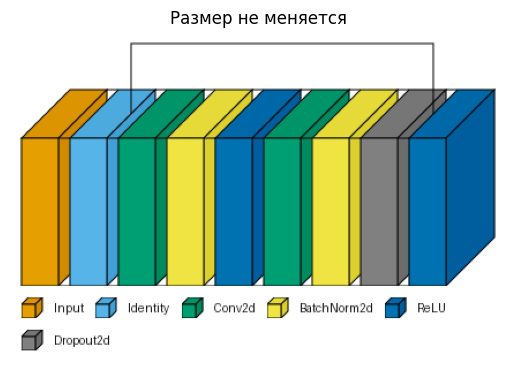

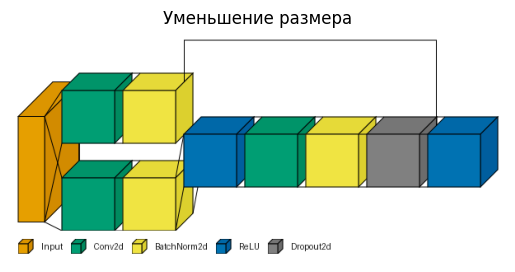

In [7]:
res_block = {
    "Размер не меняется": same_shape_block,
    "Уменьшение размера": downsample_block,
}

for block_name, block in res_block.items():
    img = visualtorch.render(
        block,
        input_shape=(4, 32, 32, 32),
        style="flow",
        legend=True,
        scale_xy=4,
        scale_z=1,
        color_map=color_map,
    )

    plt.imshow(img)
    plt.title(block_name)
    plt.axis("off")
    plt.show()

## Архитектура ResNet и изменение размерности признаков

ResNet (*Residual Network*) строится из последовательности residual-блоков. Для изображений CIFAR-10 удобно использовать вариант без раннего агрессивного уменьшения разрешения:

- начальная свёртка сохраняет размер $32 \times 32$;
- первый этап residual-блоков работает с 32 каналами;
- следующий этап увеличивает число каналов до 64 и уменьшает разрешение до $16 \times 16$;
- последний этап использует 128 каналов и разрешение $8 \times 8$.

При переходе между этапами первый блок меняет размерность с помощью `stride=2` и проекции в shortcut. Остальные блоки этапа сохраняют размерность.

Глубина зависит от количества блоков на каждом этапе. Например, конфигурация `(2, 2, 2)` содержит два residual-блока на каждом из трёх этапов.


### Global Average Pooling

После свёрточных блоков остаётся тензор карт признаков формы `(B, C, H, W)`. Перед классификатором можно усреднить каждую карту признаков по пространственным координатам с помощью `nn.AdaptiveAvgPool2d(1)`.

Для каждого канала вычисляется:

$$
z_c=\frac{1}{H \cdot W}\sum_{i=1}^{H}\sum_{j=1}^{W}u_c(i,j).
$$

В результате тензор `(B, C, H, W)` превращается в `(B, C, 1, 1)`, а после `flatten` - в `(B, C)`. Это позволяет использовать небольшой линейный классификатор независимо от конкретного пространственного размера карт.


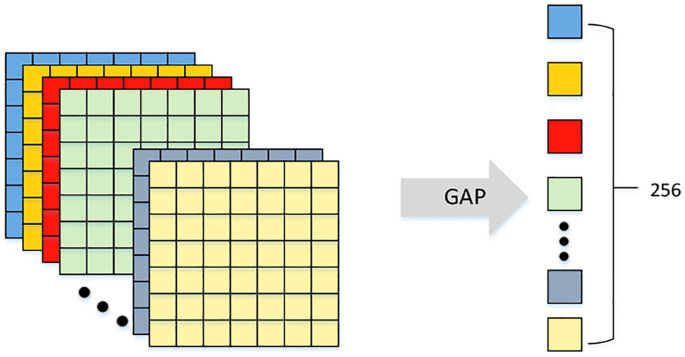

## Squeeze-and-Excitation: адаптивное перевзвешивание каналов

Свёрточная сеть формирует несколько карт признаков - каналов. Не все каналы одинаково полезны для каждого входного изображения. **SE-блок** (*Squeeze-and-Excitation*) учится оценивать важность каналов и адаптивно изменять их вклад.

SE-блок состоит из двух этапов.

**1. Squeeze.** Для каждого канала выполняется глобальное усреднение по пространственным координатам:

$$
z_c=\frac{1}{H W}\sum_{i=1}^{H}\sum_{j=1}^{W}u_c(i,j).
$$

Так карта признаков сводится к одному числу, описывающему среднюю активацию канала.

**2. Excitation.** Полученный вектор проходит через небольшую последовательность полносвязных слоёв. Первый слой уменьшает размерность, нелинейность ReLU добавляет гибкость, второй слой восстанавливает число каналов, а Sigmoid ограничивает коэффициенты диапазоном $(0,1)$:

$$
s=\sigma(W_2\,\operatorname{ReLU}(W_1z)).
$$

После этого каждый канал умножается на свой коэффициент:

$$
\widetilde{u}_c=s_c\cdot u_c.
$$

Коэффициент $s_c$ зависит от всего входного изображения, поэтому один и тот же канал может усиливаться по-разному для разных изображений.


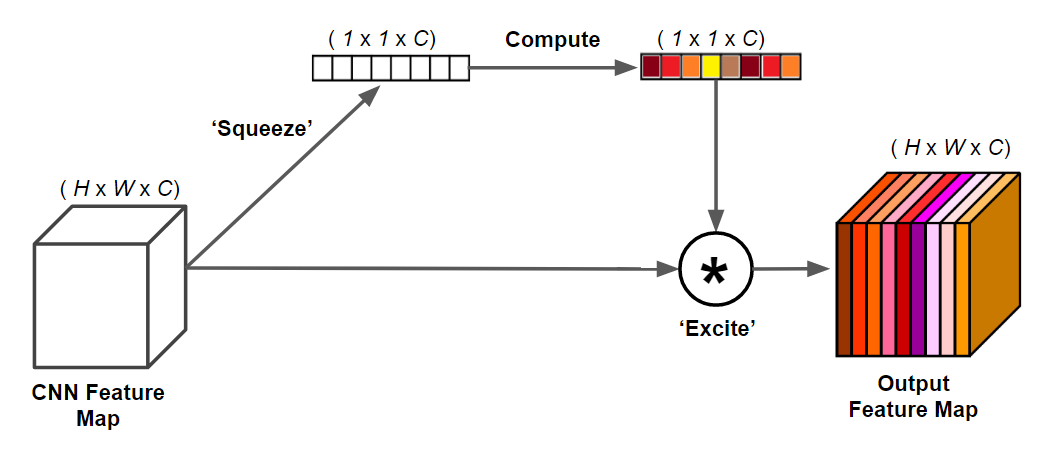

### Интуитивная идея внимания к признакам

SE-блок можно рассматривать как простой механизм **внимания к каналам** (*channel attention*). Он не выбирает отдельные пиксели и не строит пространственную карту внимания. Вместо этого он оценивает, какие карты признаков полезнее для текущего изображения.

Например, для одного изображения могут оказаться важными каналы, реагирующие на текстуру, а для другого - каналы, реагирующие на цветовые переходы. SE-блок не получает готовых правил: коэффициенты обучаются вместе с остальной сетью по функции потерь классификации.

Это не означает, что коэффициент канала напрямую показывает семантическую важность признака для человека. Это внутренний обучаемый механизм перераспределения амплитуд активаций.


In [8]:
# Реализуем SE-блок: global average pooling, компактный MLP и масштабирование каналов.
class SEBlock(nn.Module):
    """Squeeze-and-Excitation блок для адаптивного взвешивания каналов."""

    def __init__(self, channels: int, reduction: int = 16) -> None:
        super().__init__()
        hidden_channels = max(channels // reduction, 1)

        self.squeeze = nn.AdaptiveAvgPool2d(1)
        self.excitation = nn.Sequential(
            nn.Linear(channels, hidden_channels),
            nn.ReLU(inplace=True),
            nn.Linear(hidden_channels, channels),
            nn.Sigmoid(),
        )

        # Используем вспомогательный модуль для корректного отображения с помощью visualtorch.
        self.multiply = Multiply()

        # Сохраняем последние коэффициенты для последующей визуализации.
        self.last_scale: torch.Tensor | None = None

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Умножает каждый канал входного тензора на обучаемый коэффициент."""
        batch_size, channels, _, _ = x.shape

        squeezed = self.squeeze(x).view(batch_size, channels)
        scale = self.excitation(squeezed).view(batch_size, channels, 1, 1)

        self.last_scale = scale.detach()

        return self.multiply(x, scale)

In [9]:
# Проверяем форму коэффициентов SE и то, что выход сохраняет форму входной карты признаков.
se_demo = SEBlock(channels=64, reduction=16)
se_input = torch.randn(5, 64, 8, 8)
se_output = se_demo(se_input)

print("Вход SE:", tuple(se_input.shape))
print("Выход SE:", tuple(se_output.shape))
print("Форма коэффициентов:", tuple(se_demo.last_scale.shape))
print(
    "Диапазон коэффициентов:",
    float(se_demo.last_scale.min()),
    float(se_demo.last_scale.max()),
)

Вход SE: (5, 64, 8, 8)
Выход SE: (5, 64, 8, 8)
Форма коэффициентов: (5, 64, 1, 1)
Диапазон коэффициентов: 0.3599965572357178 0.6412810683250427


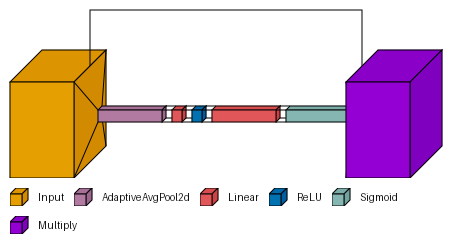

In [10]:
img = visualtorch.render(
    se_demo,
    input_shape=(5, 64, 8, 8),
    style="flow",
    legend=True,
    scale_xy=12,
    scale_z=1,
    force_detour=True,
    color_map=color_map,
)

display(img)

**Небольшое задание.** Для `channels=64` и `reduction=16` определите размер скрытого слоя MLP внутри SE-блока. Сколько линейных слоёв используется в excitation? Почему после последнего линейного слоя применяется Sigmoid?


## Сравнение архитектур: качество, параметры и вычислительные затраты

При сравнении CNN важно смотреть не только на accuracy. Более глубокая архитектура может иметь больше обучаемых параметров и выполнять больше операций на одном изображении.

В этой работе будем использовать три характеристики:

- **Accuracy** - доля правильно классифицированных изображений;
- **число обучаемых параметров** - количество скалярных значений, обновляемых оптимизатором;
- **MACs** (*multiply-accumulate operations*) - оценка числа операций умножения с накоплением для одного изображения.

MACs ниже будут оцениваться для свёрточных и линейных слоёв. Это приближённая оценка: она не включает стоимость BatchNorm, активаций, pooling и других операций, а фактическое время зависит также от устройства и реализации библиотек.


## Датасет CIFAR-10

В этой работе используем **CIFAR-10** - набор цветных изображений десяти классов. Каждое изображение имеет размер $32 \times 32$ пикселя и три цветовых канала RGB.

| Метка | Класс |
|---:|---|
| 0 | airplane |
| 1 | automobile |
| 2 | bird |
| 3 | cat |
| 4 | deer |
| 5 | dog |
| 6 | frog |
| 7 | horse |
| 8 | ship |
| 9 | truck |

В отличие от MNIST и Fashion-MNIST, здесь вход содержит три цветовых канала и более разнообразные изображения. Это делает задачу сложнее и позволяет лучше увидеть пользу более выразительных свёрточных архитектур.


## Воспроизводимость и параметры эксперимента

Зафиксируем seed и основные настройки. Это поможет сравнивать CNN и ResNet на одном и том же разбиении данных.

In [11]:
# Фиксируем seed и задаём основные гиперпараметры эксперимента в одном месте.
from pathlib import Path
import random

SEED = 42
BATCH_SIZE = 128
MAX_EPOCHS = 30
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
SCHEDULER_PATIENCE = 3
MIN_LR = 1e-6
FACTOR = 0.5
VALIDATION_SHARE = 0.10
DATA_DIR = Path("./data")

DATA_DIR.mkdir(parents=True, exist_ok=True)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

In [12]:
CLASS_NAMES = [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck",
]

## Загрузка и визуализация CIFAR-10

Загрузим исходные изображения без автоматического преобразования. Объект `datasets.CIFAR10` хранит изображения в `data`, а метки классов - в `targets`. Такой способ позволяет самостоятельно организовать разделение данных и подготовку батчей.


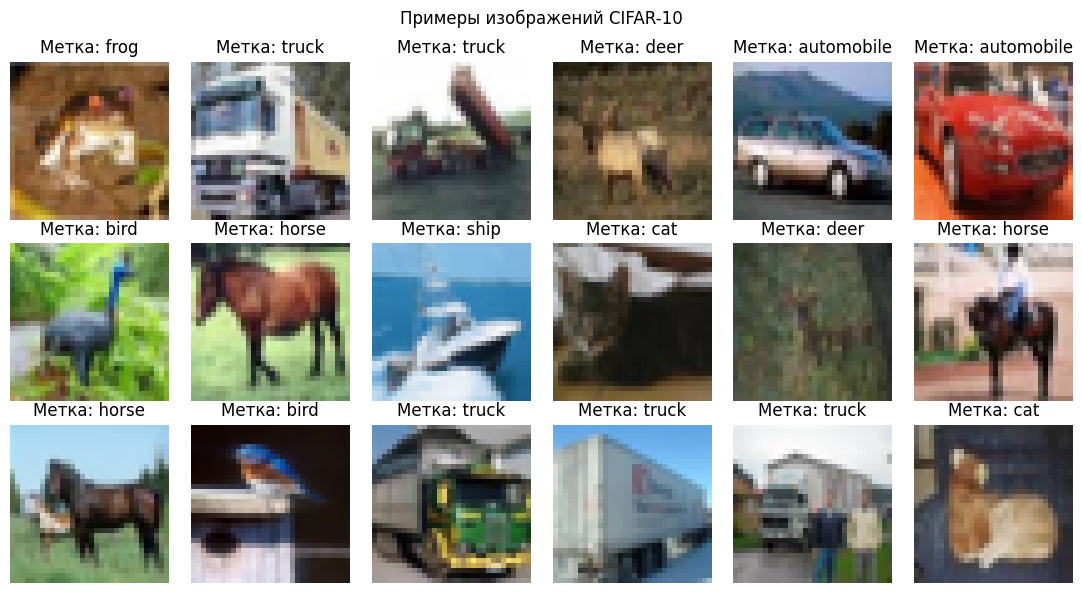

Размер обучающей части: 50000
Форма одного изображения: (32, 32, 3)


In [13]:
# Загружаем CIFAR-10 для первичного просмотра и выводим несколько изображений с метками.
from torchvision import datasets

datasets.CIFAR10.url = (
    "https://data.brainchip.com/dataset-mirror/cifar10/cifar-10-python.tar.gz"
)
train_raw = datasets.CIFAR10(root=DATA_DIR, train=True, download=True)
test_raw = datasets.CIFAR10(root=DATA_DIR, train=False, download=True)

fig, axes = plt.subplots(3, 6, figsize=(11, 6))
for index, ax in enumerate(axes.flat):
    image = train_raw.data[index]
    label = int(train_raw.targets[index])
    ax.imshow(image)
    ax.set_title(f"Метка: {CLASS_NAMES[label]}")
    ax.axis("off")

fig.suptitle("Примеры изображений CIFAR-10")
plt.tight_layout()
plt.show()

print("Размер обучающей части:", len(train_raw))
print("Форма одного изображения:", train_raw.data[0].shape)

### Баланс классов

Проверим количество объектов каждого класса в обучающей части. Это полезно сделать до обучения: сильный дисбаланс может влиять на интерпретацию accuracy и других метрик.

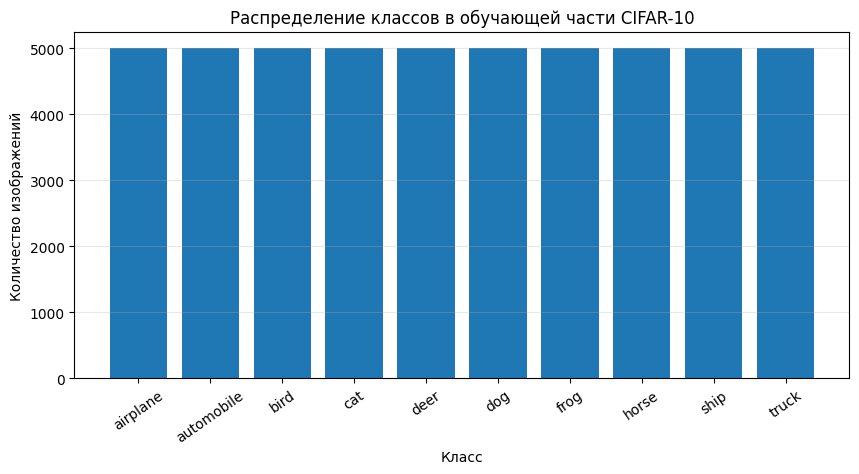

{'airplane': 5000, 'automobile': 5000, 'bird': 5000, 'cat': 5000, 'deer': 5000, 'dog': 5000, 'frog': 5000, 'horse': 5000, 'ship': 5000, 'truck': 5000}


In [14]:
# Подсчитываем количество объектов каждого класса в исходной обучающей части CIFAR-10..
class_counts = np.bincount(np.asarray(train_raw.targets), minlength=10)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(CLASS_NAMES, class_counts)
ax.set_xlabel("Класс")
ax.set_ylabel("Количество изображений")
ax.set_title("Распределение классов в обучающей части CIFAR-10")
ax.tick_params(axis="x", rotation=35)
ax.grid(axis="y", alpha=0.3)
plt.show()

print(dict(zip(CLASS_NAMES, class_counts.tolist())))

## Dataset, DataLoader и подготовка батчей на GPU

Как и в лабораторной работе № 2, исходные изображения и метки будут храниться на CPU. При формировании батча `collate_fn`:

1. объединит изображения в тензор формы `(B, H, W, C)`;
2. преобразует его в привычный для PyTorch порядок `(B, C, H, W)`;
3. перенесёт изображения и метки на выбранное устройство;
4. преобразует пиксели из диапазона `[0, 255]` в `[0, 1]`;
5. выполнит нормализацию по каналам.

Для CIFAR-10 часто используют следующие статистики обучающей выборки:

$$
\mu=(0.4914, 0.4822, 0.4465),
\qquad
\sigma=(0.2470, 0.2435, 0.2616).
$$

Нормализация выполняется отдельно для каждого цветового канала:

$$
x'_{c,h,w}=\frac{x_{c,h,w}-\mu_c}{\sigma_c}.
$$

В этой работе не используем аугментации: сравниваем влияние архитектуры на одинаковых исходных данных.

In [15]:
# Создаём collate_fn: он объединяет raw-изображения, переносит батч на device и нормализует пиксели.
from typing import TypeAlias, Union

CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD = (0.2470, 0.2435, 0.2616)
# Один элемент батча: изображение и соответствующая ему метка.
TensorPair: TypeAlias = tuple[torch.Tensor, torch.Tensor]

# Устройство можно задать строкой, объектом torch.device или индексом GPU.
DeviceLikeType: TypeAlias = Union[str, torch.device, int]


class CIFAR10Collator:
    """Подготавливает батч изображений CIFAR-10 для CNN."""

    def __init__(self, device: DeviceLikeType) -> None:
        # Сохраняем целевое устройство, на котором будут выполняться преобразования.
        if isinstance(device, int):
            device = f"cuda:{device}"
        self.device = torch.device(device)
        self.mean = torch.tensor(
            CIFAR_MEAN,
            dtype=torch.float32,
            device=self.device,
        ).view(1, 3, 1, 1)
        self.std = torch.tensor(
            CIFAR_STD,
            dtype=torch.float32,
            device=self.device,
        ).view(1, 3, 1, 1)

    def __call__(self, batch: list[TensorPair]) -> TensorPair:
        # Разделяем список элементов батча на изображения и соответствующие метки.
        images, targets = zip(*batch)

        # Объединяем изображения [H, W, C] в батч [B, H, W, C].
        images = torch.stack(images)

        # Переставляем оси в формат NCHW, используемый Conv2d.
        images = images.permute(0, 3, 1, 2).contiguous()

        # Переносим изображения на устройство и переводим значения в диапазон [0, 1].
        images = images.to(self.device, dtype=torch.float32) / 255.0

        # Объединяем метки и переносим их на то же устройство.
        targets = torch.tensor(targets, dtype=torch.long, device=self.device)

        # Нормализуем каждый RGB-канал с помощью broadcast.
        images = (images - self.mean) / self.std

        # Возвращаем готовый батч признаков и меток.
        return images, targets

## Разделение на train, validation и test

- **train** используется для вычисления градиентов и обновления параметров;
- **validation** используется для наблюдения за качеством и выбора настроек;
- **test** используется для итоговой оценки уже выбранной модели.

Выделим 10% официальной обучающей части CIFAR-10 под validation. Официальную тестовую часть не используем до финальной оценки.

In [16]:
# Разделяем обучающую часть CIFAR-10 на train и validation, сохраняя test отдельно.
from torch.utils.data import DataLoader, TensorDataset, Subset

train_full_dataset = TensorDataset(
    torch.from_numpy(train_raw.data),
    torch.tensor(train_raw.targets, dtype=torch.long),
)
test_dataset = TensorDataset(
    torch.from_numpy(test_raw.data),
    torch.tensor(test_raw.targets, dtype=torch.long),
)

split_generator = torch.Generator().manual_seed(SEED)
permuted_indices = torch.randperm(
    len(train_full_dataset), generator=split_generator
).tolist()

validation_size = int(len(permuted_indices) * VALIDATION_SHARE)
validation_indices = permuted_indices[:validation_size]
train_indices = permuted_indices[validation_size:]

train_dataset = Subset(train_full_dataset, train_indices)
validation_dataset = Subset(train_full_dataset, validation_indices)

print("Train:", len(train_dataset))
print("Validation:", len(validation_dataset))
print("Test:", len(test_dataset))

Train: 45000
Validation: 5000
Test: 10000


In [17]:
# Создаём все DataLoader с одним collator.
collator = CIFAR10Collator(device=device)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
    num_workers=0,
    collate_fn=collator,
)
validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    collate_fn=collator,
)
test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    collate_fn=collator,
)

features_batch, labels_batch = next(iter(train_loader))
print("Форма признаков:", tuple(features_batch.shape))
print("Форма меток:", tuple(labels_batch.shape))
print("Тип признаков:", features_batch.dtype)
print("Тип меток:", labels_batch.dtype)

Форма признаков: (128, 3, 32, 32)
Форма меток: (128,)
Тип признаков: torch.float32
Тип меток: torch.int64


## Базовая CNN для CIFAR-10

Сначала реализуем обычную свёрточную сеть без остаточных связей. Она будет точкой отсчёта для сравнения с ResNet.

В качестве простой архитектуры используем три свёрточных этапа с увеличением числа каналов. В конце применим global average pooling и линейный классификатор. Такой классификатор компактнее, чем `Flatten` с большим полносвязным слоем.


In [18]:
# Определяем базовую CNN для CIFAR-10 с тремя свёрточными этапами.
class BaselineCNN(nn.Module):
    """Базовая CNN без residual connections и SE-блоков."""

    def __init__(self, num_classes: int = 10) -> None:
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Dropout2d(0.1),
            nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Dropout2d(0.2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.Dropout2d(0.3),
        )
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Linear(128, num_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Возвращает логиты для каждого изображения батча."""
        x = self.features(x)
        x = self.pool(x).flatten(1)
        return self.classifier(x)

In [19]:
# Проверяем формы выходов базовой CNN и подсчитываем число обучаемых параметров.
def count_parameters(model: nn.Module) -> int:
    """Возвращает число обучаемых параметров модели."""
    return sum(
        parameter.numel() for parameter in model.parameters() if parameter.requires_grad
    )


baseline_model = BaselineCNN().to(device)
with torch.no_grad():
    baseline_logits = baseline_model(features_batch)

print("Форма входа:", tuple(features_batch.shape))
print("Форма логитов:", tuple(baseline_logits.shape))
print(f"Обучаемых параметров: {count_parameters(baseline_model):,}")

Форма входа: (128, 3, 32, 32)
Форма логитов: (128, 10)
Обучаемых параметров: 141,034


In [20]:
import io
from typing import Any
from IPython.display import Image
from visualtorch.utils.utils import InputShape
from visualtorch.render import Style


def animate(
    model: nn.Module,
    input_shape: InputShape,
    style: Style = "graph",
    frame_duration: int = 600,
    final_hold_duration: int = 1500,
    **kwargs: Any,
) -> Image:
    frames = visualtorch.animate(
        model,
        input_shape,
        style=style,
        **kwargs,
    )

    durations = [frame_duration] * (len(frames) - 1) + [final_hold_duration]

    buf = io.BytesIO()
    frames[0].save(
        buf,
        format="GIF",
        save_all=True,
        append_images=frames[1:],
        duration=durations,
        loop=0,
    )

    return Image(data=buf.getvalue(), format="gif")

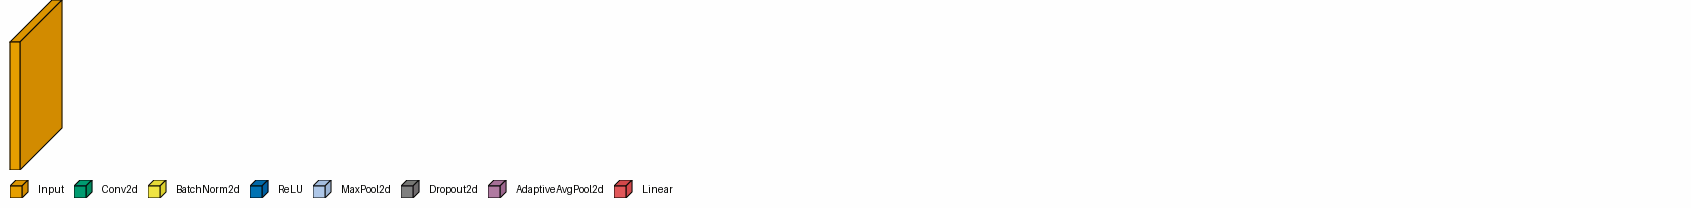

In [21]:
animate(
    baseline_model.cpu(),
    input_shape=(128, 3, 32, 32),
    style="flow",
    legend=True,
    scale_xy=4,
    scale_z=1,
    color_map=color_map,
    frame_duration=500,
    final_hold_duration=3000,
)

**Небольшое задание.** Проследите за формами тензора внутри `BaselineCNN`. Как меняются пространственные размеры после каждого `MaxPool2d`? Почему перед `Linear` получается 128 признаков на изображение?


## Реализация ResNet с SE-блоками

Теперь соберём ResNet из уже рассмотренных компонентов:

- `BasicBlock` выполняет остаточное преобразование и при необходимости меняет размерность;
- `SEBlock` оценивает коэффициенты важности каналов;
- `ResNetSE` объединяет начальную свёртку, несколько этапов residual-блоков, global average pooling и классификатор.

Внутри residual-блока SE-блок применяется к результату второй свёртки **до сложения с shortcut**:

$$
y=\operatorname{ReLU}(\operatorname{SE}(F(x))+S(x)).
$$

Ниже дан каркас `ResNetSE`. Классы `BasicBlock` и `SEBlock` уже реализованы выше. Ваша задача - самостоятельно собрать этапы сети и реализовать прямой проход. В сетях с SE-блоками обычно не применяется `Dropout2d`, так как случайное обнуление целых каналов конфликтует с механизмом поканального внимания.

In [ ]:
# Каркас ResNet с SE: заполните отмеченные места, используя реализованный ранее BasicBlock как пример.
class SEBasicBlock(nn.Module):
    """Residual-блок с SE-перевзвешиванием перед сложением с shortcut."""

    expansion = 1

    def __init__(
        self,
        in_channels: int,
        out_channels: int,
        stride: int = 1,
        reduction: int = 16,
    ) -> None:
        super().__init__()

        # Создайте две свёртки 3x3 с BatchNorm; первая учитывает stride.
        # Добавьте ReLU после первой BatchNorm.

        # SE-блок
        self.se = SEBlock(out_channels, reduction=reduction)

        # Если размерность меняется, создайте shortcut с Conv2d 1x1 и BatchNorm2d;
        #       иначе используйте nn.Identity().

        ...

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Сохраните shortcut, вычислите residual-ветвь, примените SE,
        #       сложите ветви и примените итоговую ReLU.
        ...


class ResNetSE(nn.Module):
    """ResNet для CIFAR-10 с SE-блоками в каждом residual-блоке."""

    def __init__(
        self,
        num_classes: int = 10,
        blocks_per_stage: tuple[int, int, int] = (2, 2, 2),
        base_channels: int = 32,
        reduction: int = 16,
    ) -> None:
        super().__init__()

        self.in_channels = base_channels

        # Создайте начальную свёртку 3 -> base_channels, BatchNorm и ReLU (stem).

        self.stage1 = self._make_stage(
            base_channels, blocks_per_stage[0], stride=1, reduction=reduction
        )
        self.stage2 = self._make_stage(
            base_channels * 2, blocks_per_stage[1], stride=2, reduction=reduction
        )
        self.stage3 = self._make_stage(
            base_channels * 4, blocks_per_stage[2], stride=2, reduction=reduction
        )

        # Добавьте AdaptiveAvgPool2d(1) и Linear(4*base_channels, num_classes).
        ...

    def _make_stage(
        self, channels: int, blocks: int, stride: int, reduction: int
    ) -> nn.Sequential:
        """Создаёт этап residual-блоков с нужным числом каналов."""
        layers = [
            SEBasicBlock(self.in_channels, channels, stride=stride, reduction=reduction)
        ]
        self.in_channels = channels
        for _ in range(1, blocks):
            layers.append(SEBasicBlock(self.in_channels, channels, stride=1))
        return nn.Sequential(*layers)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Последовательно примените stem и три этапа,
        #       затем global average pooling, flatten и классификатор.
        ...

После реализации проверьте, что сеть принимает батч формы `(B, 3, 32, 32)` и возвращает `(B, 10)`. Также проверьте, что при переходе между этапами пространственное разрешение уменьшается, а число каналов увеличивается.

Для сравнения полезно иметь ResNet без SE. Его можно получить той же схемой, заменив `SEBasicBlock` на обычный `BasicBlock` из предыдущего раздела. Чтобы не дублировать всю реализацию, ниже будет приведён отдельный класс, использующий те же настройки глубины.


In [23]:
# Проверяем реализацию ResNetSE; выполните ячейку после заполнения каркаса.
resnet_se_model = ResNetSE(
    num_classes=10,
    blocks_per_stage=(2, 2, 2),
    base_channels=32,
    reduction=16,
).to(device)

with torch.no_grad():
    resnet_se_logits = resnet_se_model(features_batch)

print("Форма входа:", tuple(features_batch.shape))
print("Форма логитов ResNetSE:", tuple(resnet_se_logits.shape))
print(f"Обучаемых параметров: {count_parameters(resnet_se_model):,}")

Форма входа: (128, 3, 32, 32)
Форма логитов ResNetSE: (128, 10)
Обучаемых параметров: 702,470


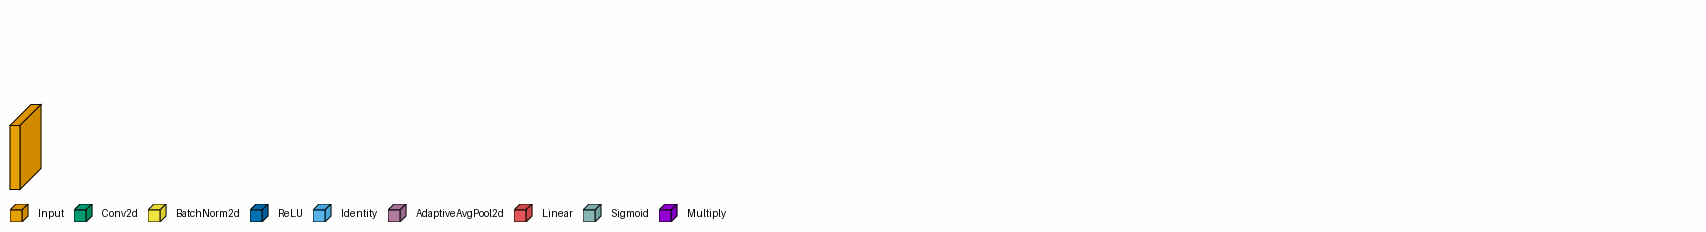

In [24]:
animate(
    resnet_se_model.cpu(),
    input_shape=(128, 3, 32, 32),
    style="flow",
    legend=True,
    scale_xy=2,
    force_detour=True,
    color_map=color_map,
    frame_duration=500,
    final_hold_duration=3000,
)

### ResNet без SE для контрольного сравнения

Чтобы оценить вклад именно SE-механизма, сравним две сети с одинаковым числом residual-блоков: обычную ResNet и ResNet с SE. Вариант ниже использует `BasicBlock`, реализованный ранее.

In [25]:
# Реализуем ResNet без SE на тех же этапах, чтобы отделить эффект residual connections от SE.
class ResNet(nn.Module):
    """ResNet для CIFAR-10 без SE-блоков."""

    def __init__(
        self,
        num_classes: int = 10,
        blocks_per_stage: tuple[int, int, int] = (2, 2, 2),
        base_channels: int = 32,
    ) -> None:
        super().__init__()
        self.in_channels = base_channels

        self.stem = nn.Sequential(
            nn.Conv2d(3, base_channels, kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(base_channels),
            nn.ReLU(inplace=True),
        )
        self.stage1 = self._make_stage(base_channels, blocks_per_stage[0], stride=1)
        self.stage2 = self._make_stage(base_channels * 2, blocks_per_stage[1], stride=2)
        self.stage3 = self._make_stage(base_channels * 4, blocks_per_stage[2], stride=2)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Linear(base_channels * 4, num_classes)

    def _make_stage(self, channels: int, blocks: int, stride: int) -> nn.Sequential:
        """Создаёт этап residual-блоков с нужным числом каналов."""
        layers = [BasicBlock(self.in_channels, channels, stride=stride)]
        self.in_channels = channels
        for _ in range(1, blocks):
            layers.append(BasicBlock(self.in_channels, channels, stride=1))
        return nn.Sequential(*layers)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """Возвращает логиты десяти классов CIFAR-10."""
        x = self.stem(x)
        x = self.stage1(x)
        x = self.stage2(x)
        x = self.stage3(x)
        x = self.pool(x).flatten(1)
        return self.classifier(x)

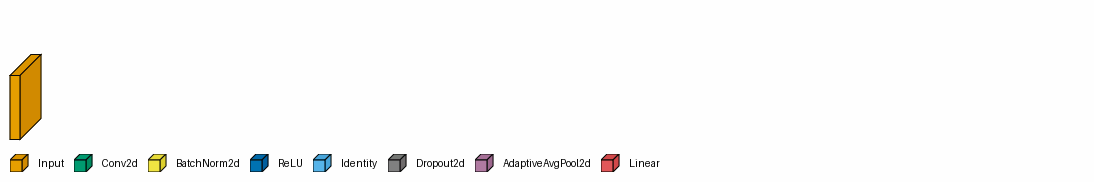

In [26]:
resnet_model = ResNet(
    num_classes=10,
    blocks_per_stage=(2, 2, 2),
    base_channels=32,
)

animate(
    resnet_model,
    input_shape=(128, 3, 32, 32),
    style="flow",
    legend=True,
    scale_xy=2,
    force_detour=True,
    color_map=color_map,
    frame_duration=500,
    final_hold_duration=3000,
)

**Небольшое задание.** Сравните `ResNet` и `ResNetSE`. Какие части архитектур совпадают? Где именно добавляется SE-блок? Почему сравнение этих двух моделей позволяет точнее оценить влияние перевзвешивания каналов, чем сравнение ResNetSE только с базовой CNN?


## Обучение через PyTorch Lightning

Обучим три модели на одном разбиении данных:

1. базовую CNN;
2. ResNet без SE;
3. ResNet с SE-блоками.

Число эпох и остальные параметры обучения задаются выше в одной ячейке.

In [ ]:
%pip install lightning -qU

In [27]:
import os
import sys

sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), "..")))

In [28]:
# Обучаем базовую CNN с помощью LitModel и сохраняем лучшую модель по validation loss.
from templates.lit import LitModel

baseline_lit = LitModel(
    model=BaselineCNN,
    num_classes=10,
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    use_reduce_lr_on_plateau=True,
    scheduler_patience=SCHEDULER_PATIENCE,
    min_lr=MIN_LR,
    factor=FACTOR,
    seed=SEED,
)

baseline_metrics = baseline_lit.fit(
    train_loader=train_loader,
    validation_loader=validation_loader,
    epochs=MAX_EPOCHS,
    patience=MAX_EPOCHS,
)

baseline_best_model = baseline_lit.to(device).model.eval()

In [29]:
# Обучаем ResNet без SE на том же наборе данных и с теми же настройками оптимизатора.
resnet_lit = LitModel(
    model=ResNet,
    num_classes=10,
    blocks_per_stage=(2, 2, 2),
    base_channels=32,
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    use_reduce_lr_on_plateau=True,
    scheduler_patience=SCHEDULER_PATIENCE,
    min_lr=MIN_LR,
    factor=FACTOR,
    seed=SEED,
)

resnet_metrics = resnet_lit.fit(
    train_loader=train_loader,
    validation_loader=validation_loader,
    epochs=MAX_EPOCHS,
    patience=MAX_EPOCHS,
)

resnet_best_model = resnet_lit.to(device).model.eval()

**Важно:** следующая ячейка предполагает, что каркас `ResNetSE` уже реализован. Если вы ещё не заполнили `SEBasicBlock` и `ResNetSE`, вернитесь к соответствующей ячейке.


In [30]:
# Обучаем ResNet с SE-блоками для оценки влияния адаптивного перевзвешивания каналов.
resnet_se_lit = LitModel(
    model=ResNetSE,
    num_classes=10,
    blocks_per_stage=(2, 2, 2),
    base_channels=32,
    reduction=16,
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    use_reduce_lr_on_plateau=True,
    scheduler_patience=SCHEDULER_PATIENCE,
    min_lr=MIN_LR,
    factor=FACTOR,
    seed=SEED,
)

resnet_se_metrics = resnet_se_lit.fit(
    train_loader=train_loader,
    validation_loader=validation_loader,
    epochs=MAX_EPOCHS,
    patience=MAX_EPOCHS,
)

resnet_se_best_model = resnet_se_lit.to(device).model.eval()

## Построение графиков обучения

На графиках сравним обучающую и валидационную функции потерь, а также accuracy.


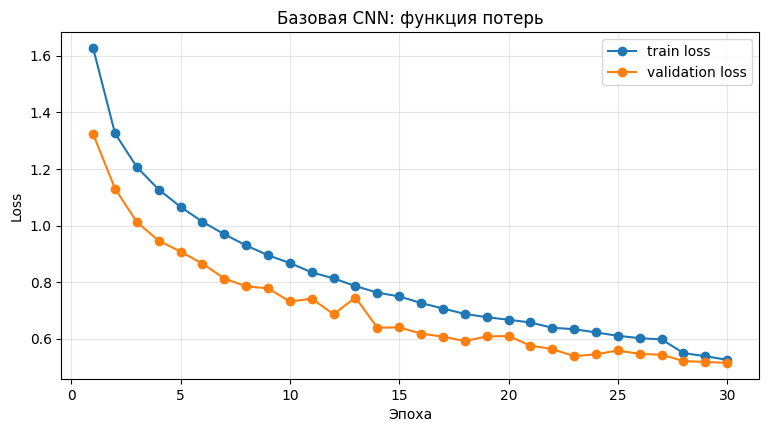

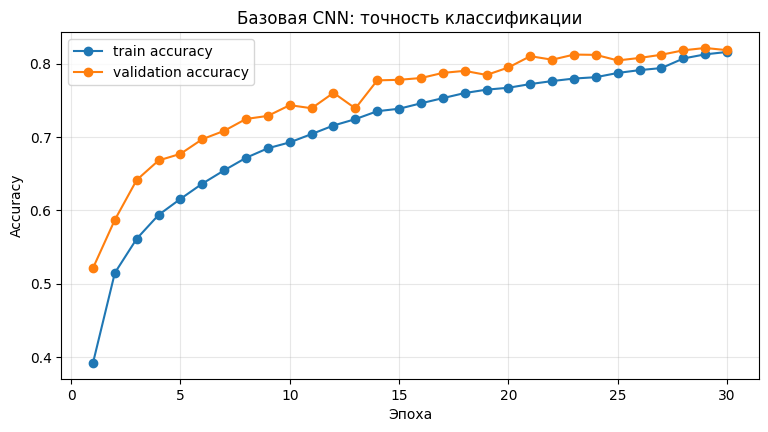

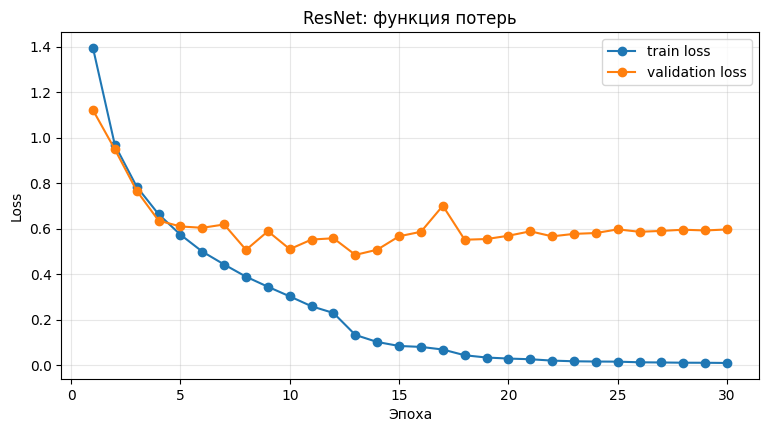

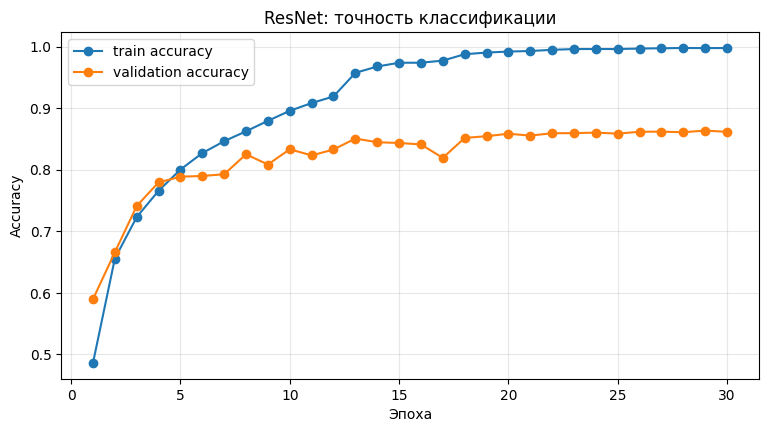

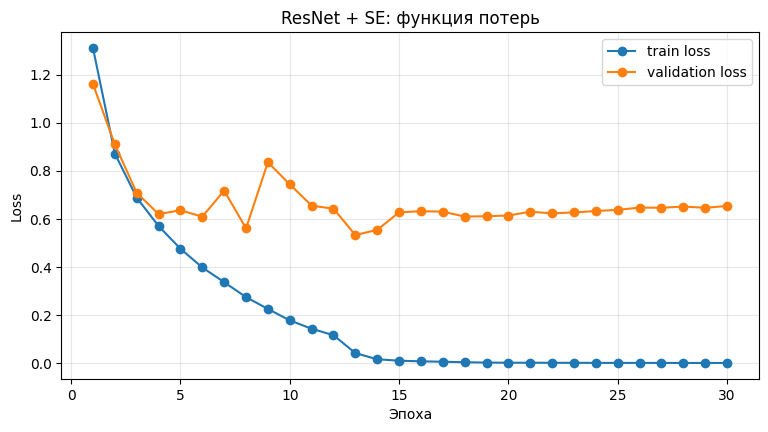

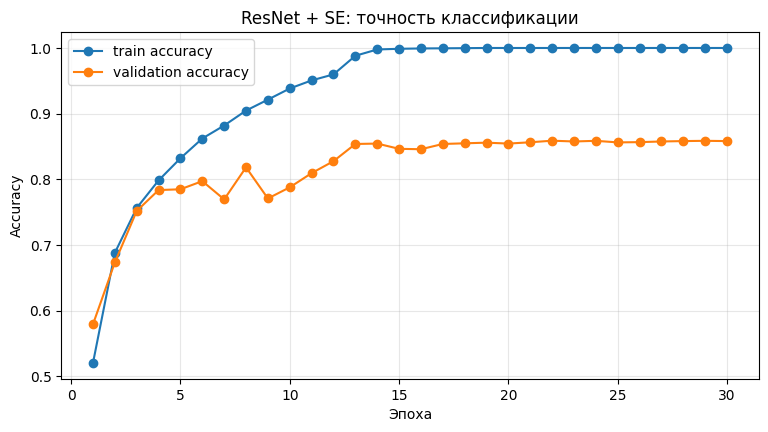

In [31]:
# Преобразуем журналы Lightning в историю по эпохам и строим графики loss и accuracy.
import pandas as pd


def epoch_history(metrics: pd.DataFrame) -> pd.DataFrame:
    """Возвращает последние значения метрик для каждой эпохи."""
    return metrics.groupby("epoch")[
        ["train_loss", "train_accuracy", "val_loss", "val_accuracy"]
    ].last()


def plot_history(history: pd.DataFrame, title: str) -> None:
    """Строит отдельные графики train/validation loss и accuracy."""
    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.plot(history.index + 1, history["train_loss"], marker="o", label="train loss")
    ax.plot(history.index + 1, history["val_loss"], marker="o", label="validation loss")
    ax.set(xlabel="Эпоха", ylabel="Loss", title=f"{title}: функция потерь")
    ax.grid(alpha=0.3)
    ax.legend()
    plt.show()

    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.plot(
        history.index + 1, history["train_accuracy"], marker="o", label="train accuracy"
    )
    ax.plot(
        history.index + 1,
        history["val_accuracy"],
        marker="o",
        label="validation accuracy",
    )
    ax.set(xlabel="Эпоха", ylabel="Accuracy", title=f"{title}: точность классификации")
    ax.grid(alpha=0.3)
    ax.legend()
    plt.show()


baseline_history = epoch_history(baseline_metrics)
resnet_history = epoch_history(resnet_metrics)
resnet_se_history = epoch_history(resnet_se_metrics)

plot_history(baseline_history, "Базовая CNN")
plot_history(resnet_history, "ResNet")
plot_history(resnet_se_history, "ResNet + SE")

**Исследование.** Сравните графики трёх моделей. Какая архитектура быстрее уменьшает validation loss? Уменьшается ли разрыв между train и validation accuracy? Не делайте вывод только по последней эпохе: учитывайте всю динамику обучения.


## Сравнение числа параметров и вычислительных затрат

Подсчитаем обучаемые параметры и приблизительное число MACs для одного изображения размером $32 \times 32$. Для MACs используем forward hooks на `Conv2d` и `Linear`.

Для свёртки число MACs оценивается как число выходных элементов, умноженное на число операций для одного выходного элемента:

$$
MACs_{conv}=B\cdot H_{out}\cdot W_{out}\cdot C_{out}
\cdot\frac{C_{in}}{groups}\cdot K_H\cdot K_W.
$$

Для линейного слоя:

$$
MACs_{linear}=B\cdot N_{out}\cdot N_{in}.
$$

В таблице будем считать MACs для батча из одного изображения.


In [32]:
# Оцениваем MACs для Conv2d и Linear с помощью forward hooks.
def estimate_macs(
    model: nn.Module, input_shape: tuple[int, ...], target_device: torch.device
) -> int:
    """Приближённо считает MACs свёрточных и линейных слоёв для одного примера."""
    macs = 0
    hooks = []

    def conv_hook(module: nn.Conv2d, inputs, output):
        nonlocal macs
        batch_size, out_channels, out_height, out_width = output.shape
        kernel_ops = (
            module.in_channels
            // module.groups
            * module.kernel_size[0]
            * module.kernel_size[1]
        )
        macs += batch_size * out_channels * out_height * out_width * kernel_ops

    def linear_hook(module: nn.Linear, inputs, output):
        nonlocal macs
        macs += output.numel() * module.in_features

    for module in model.modules():
        if isinstance(module, nn.Conv2d):
            hooks.append(module.register_forward_hook(conv_hook))
        elif isinstance(module, nn.Linear):
            hooks.append(module.register_forward_hook(linear_hook))

    was_training = model.training
    model.eval()
    with torch.no_grad():
        sample = torch.zeros(input_shape, device=target_device)
        model(sample)

    for hook in hooks:
        hook.remove()
    model.train(was_training)
    return int(macs)

In [33]:
# Формируем таблицу архитектурных характеристик трёх обученных моделей.
comparison_models = {
    "Базовая CNN": baseline_best_model,
    "ResNet": resnet_best_model,
    "ResNet + SE": resnet_se_best_model,
}

comparison_rows = []
for model_name, model in comparison_models.items():
    comparison_rows.append(
        {
            "Архитектура": model_name,
            "Параметры": count_parameters(model),
            "MACs на изображение": estimate_macs(model, (1, 3, 32, 32), device),
        }
    )

architecture_table = pd.DataFrame(comparison_rows)
architecture_table

,Архитектура,Параметры,MACs на изображение
0,Базовая CNN,141034,29197568
1,ResNet,696618,105743616
2,ResNet + SE,702470,105748992


In [34]:
# Сопоставляем лучшие validation-метрики с числом параметров и MACs.
def best_validation_summary(history: pd.DataFrame) -> dict[str, float]:
    """Возвращает лучшую validation accuracy и соответствующий validation loss."""
    best_index = history["val_accuracy"].idxmax()
    return {
        "Лучшая val accuracy": float(history.loc[best_index, "val_accuracy"]),
        "Val loss при ней": float(history.loc[best_index, "val_loss"]),
        "Эпоха": int(best_index) + 1,
    }


histories = {
    "Базовая CNN": baseline_history,
    "ResNet": resnet_history,
    "ResNet + SE": resnet_se_history,
}

for row in comparison_rows:
    row.update(best_validation_summary(histories[row["Архитектура"]]))

architecture_table = pd.DataFrame(comparison_rows)
architecture_table

,Архитектура,Параметры,MACs на изображение,Лучшая val accuracy,Val loss при ней,Эпоха
0,Базовая CNN,141034,29197568,0.8216,0.518704,29
1,ResNet,696618,105743616,0.8638,0.592639,29
2,ResNet + SE,702470,105748992,0.8588,0.623096,22


**Исследование.** Какая модель имеет больше параметров? Насколько добавление SE-блоков увеличивает размер ResNet? Сопоставьте изменение validation accuracy с изменением числа параметров и MACs. Всегда ли увеличение вычислительных затрат приводит к пропорциональному росту качества?


## Визуализация коэффициентов SE для разных изображений

SE-блок формирует отдельный набор коэффициентов для каждого изображения в батче. Посмотрим, как отличаются коэффициенты каналов для нескольких изображений разных классов.

Для визуализации возьмём один из SE-блоков последнего этапа сети. В нём каналы соответствуют более сложным признакам, чем в начальных слоях. Отобразим коэффициенты в виде тепловой карты: строки - изображения, столбцы - каналы.


In [35]:
# Находим SE-блоки внутри ResNetSE и выбираем последний из них для анализа.
se_modules = [
    module for module in resnet_se_best_model.modules() if isinstance(module, SEBlock)
]
print("Количество SE-блоков:", len(se_modules))

if not se_modules:
    raise RuntimeError("В ResNetSE не найдены экземпляры SEBlock.")

selected_se_module = se_modules[-1]

Количество SE-блоков: 6


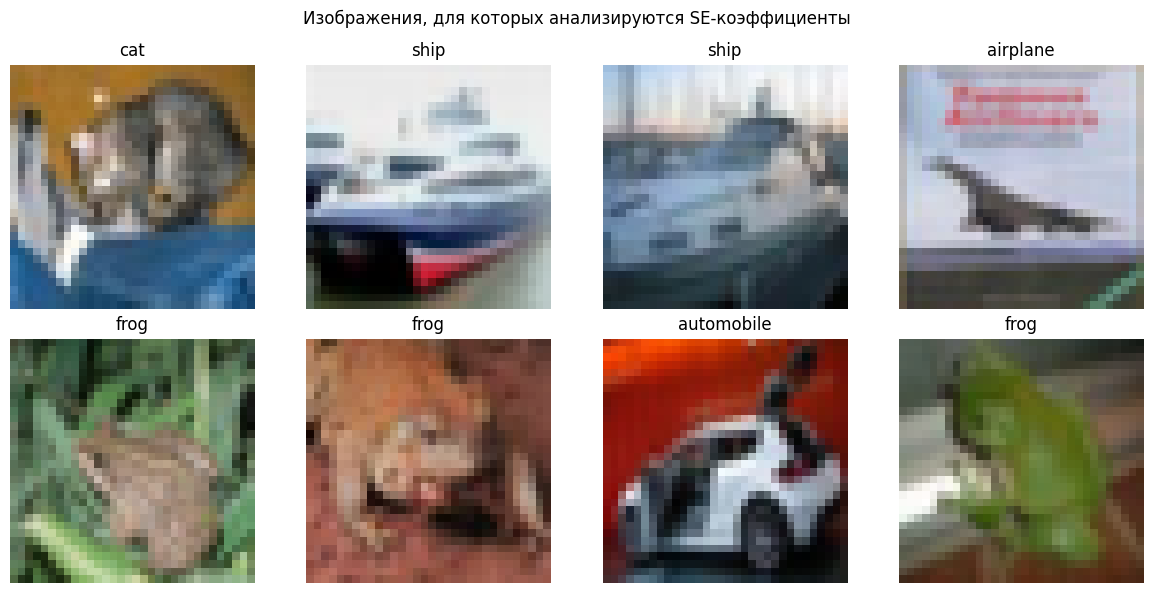

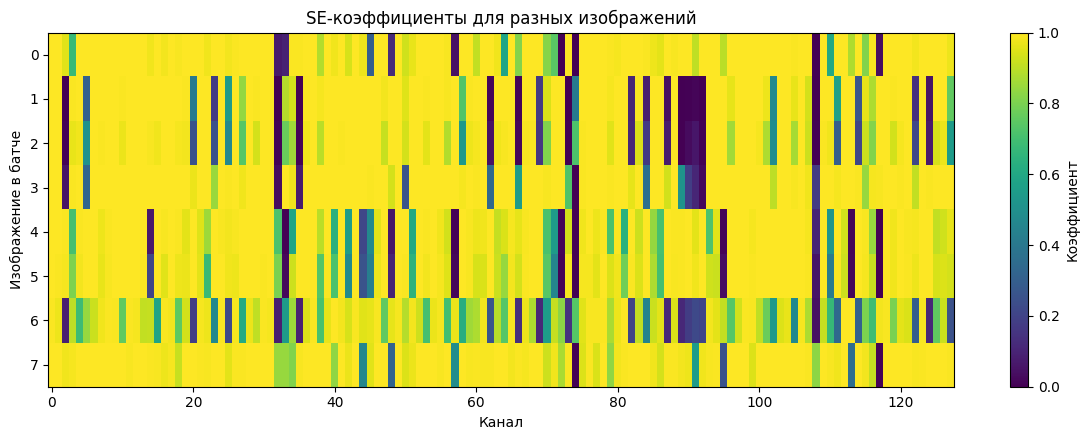

In [36]:
# Получаем несколько изображений разных классов и сохраняем коэффициенты выбранного SE-блока.
@torch.inference_mode()
def collect_se_scales(
    model: nn.Module,
    loader: DataLoader,
    se_module: SEBlock,
    num_images: int = 8,
) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
    """Возвращает изображения, метки и коэффициенты выбранного SE-блока."""
    model.eval()
    image_batches = []
    label_batches = []
    scale_batches = []

    for images, labels in loader:
        model(images)
        if se_module.last_scale is None:
            raise RuntimeError("SE-блок не сохранил коэффициенты.")

        image_batches.append(images.detach().cpu())
        label_batches.append(labels.detach().cpu())
        scale_batches.append(se_module.last_scale.detach().cpu())

        if sum(batch.shape[0] for batch in image_batches) >= num_images:
            break

    images = torch.cat(image_batches)[:num_images]
    labels = torch.cat(label_batches)[:num_images]
    scales = torch.cat(scale_batches)[:num_images, :, 0, 0]
    return images, labels, scales


se_images, se_labels, se_scales = collect_se_scales(
    resnet_se_best_model,
    test_loader,
    selected_se_module,
    num_images=8,
)

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for index, ax in enumerate(axes.flat):
    image = se_images[index].permute(1, 2, 0).numpy()
    image = image * np.asarray(CIFAR_STD) + np.asarray(CIFAR_MEAN)
    image = np.clip(image, 0, 1)
    ax.imshow(image)
    ax.set_title(CLASS_NAMES[int(se_labels[index])])
    ax.axis("off")
fig.suptitle("Изображения, для которых анализируются SE-коэффициенты")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(12, 4.5))
heatmap = ax.imshow(se_scales.numpy(), aspect="auto", cmap="viridis", vmin=0, vmax=1)
ax.set(
    xlabel="Канал",
    ylabel="Изображение в батче",
    title="SE-коэффициенты для разных изображений",
)
fig.colorbar(heatmap, ax=ax, label="Коэффициент")
plt.tight_layout()
plt.show()

Обратите внимание: у разных изображений коэффициенты могут отличаться. При этом нельзя автоматически утверждать, что канал с большим коэффициентом соответствует конкретному визуальному объекту. Чтобы интерпретировать отдельный канал, потребовался бы дополнительный анализ его активаций.

**Небольшое исследование.** Найдите каналы, коэффициенты которых заметно различаются между выбранными изображениями. Есть ли каналы, коэффициенты которых почти не меняются? Как можно проверить, действительно ли изменение коэффициента влияет на предсказание модели?


## Итоговая оценка на тестовой выборке

Тестовую выборку не использовали для обновления весов и выбора архитектуры. Теперь оценим три основные модели на test. Функция ниже возвращает истинные метки, предсказания и вероятности классов.


In [37]:
# Получаем предсказанные классы, истинные метки и вероятности для всей тестовой выборки.
@torch.inference_mode()
def collect_predictions(
    model: nn.Module,
    loader: DataLoader,
    target_device: torch.device,
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Возвращает истинные метки, предсказания и вероятности классов."""
    model.eval()

    all_targets: list[np.ndarray] = []
    all_predictions: list[np.ndarray] = []
    all_probabilities: list[np.ndarray] = []

    for features, labels in loader:
        # В этой работе collator уже переносит изображения на device.
        features = features.to(target_device)
        logits = model(features)
        probabilities = torch.softmax(logits, dim=1)
        predictions = logits.argmax(dim=1)

        all_targets.append(labels.cpu().numpy())
        all_predictions.append(predictions.cpu().numpy())
        all_probabilities.append(probabilities.cpu().numpy())

    return (
        np.concatenate(all_targets),
        np.concatenate(all_predictions),
        np.concatenate(all_probabilities),
    )


Базовая CNN
              precision    recall  f1-score   support

    airplane     0.8481    0.7870    0.8164      1000
  automobile     0.9167    0.9350    0.9257      1000
        bird     0.7315    0.7330    0.7323      1000
         cat     0.6854    0.6450    0.6646      1000
        deer     0.7986    0.7970    0.7978      1000
         dog     0.7490    0.7790    0.7637      1000
        frog     0.8256    0.8850    0.8542      1000
       horse     0.8364    0.8540    0.8451      1000
        ship     0.9099    0.8890    0.8993      1000
       truck     0.9011    0.9020    0.9015      1000

    accuracy                         0.8206     10000
   macro avg     0.8202    0.8206    0.8201     10000
weighted avg     0.8202    0.8206    0.8201     10000



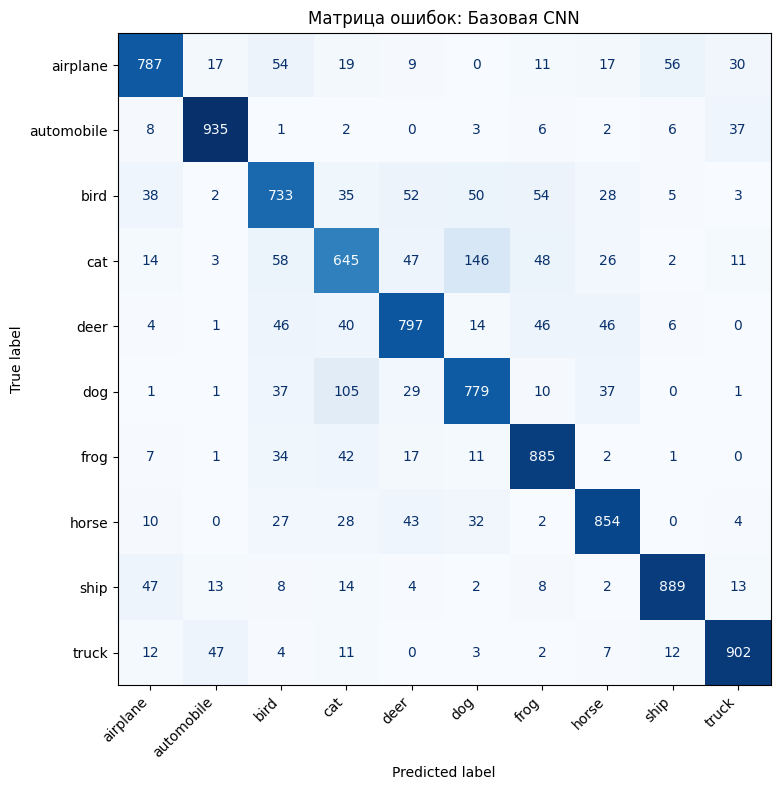


ResNet
              precision    recall  f1-score   support

    airplane     0.8884    0.8280    0.8571      1000
  automobile     0.9158    0.9350    0.9253      1000
        bird     0.8544    0.7040    0.7719      1000
         cat     0.6904    0.7070    0.6986      1000
        deer     0.8465    0.8380    0.8422      1000
         dog     0.7336    0.8070    0.7686      1000
        frog     0.8151    0.9170    0.8631      1000
       horse     0.9017    0.8810    0.8912      1000
        ship     0.8908    0.9380    0.9138      1000
       truck     0.9214    0.8790    0.8997      1000

    accuracy                         0.8434     10000
   macro avg     0.8458    0.8434    0.8432     10000
weighted avg     0.8458    0.8434    0.8432     10000



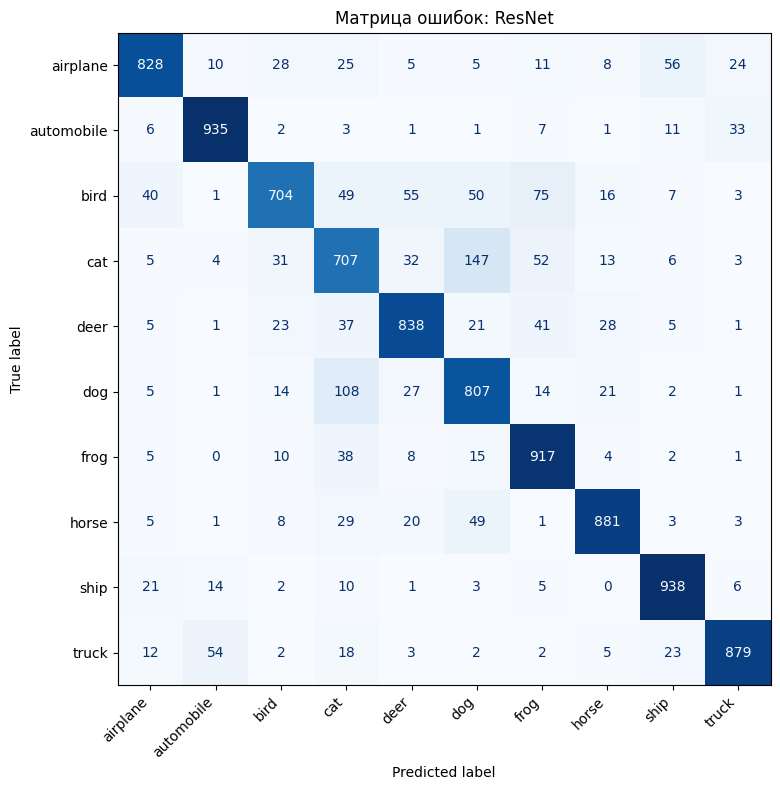


ResNet + SE
              precision    recall  f1-score   support

    airplane     0.8867    0.8220    0.8531      1000
  automobile     0.9164    0.9430    0.9295      1000
        bird     0.7840    0.8020    0.7929      1000
         cat     0.7260    0.6490    0.6853      1000
        deer     0.8070    0.8280    0.8174      1000
         dog     0.7389    0.8150    0.7751      1000
        frog     0.8669    0.8860    0.8764      1000
       horse     0.9057    0.8550    0.8796      1000
        ship     0.9029    0.9300    0.9163      1000
       truck     0.9102    0.9120    0.9111      1000

    accuracy                         0.8442     10000
   macro avg     0.8445    0.8442    0.8437     10000
weighted avg     0.8445    0.8442    0.8437     10000



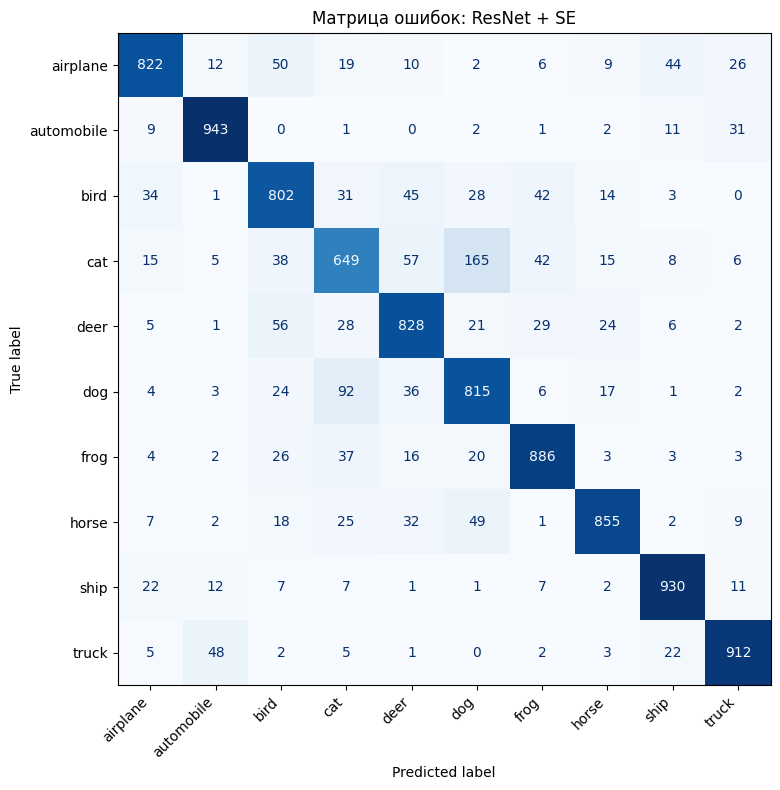

In [38]:
# Считаем classification report и confusion matrix для трёх архитектур.
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    confusion_matrix,
)

test_models = {
    "Базовая CNN": baseline_best_model,
    "ResNet": resnet_best_model,
    "ResNet + SE": resnet_se_best_model,
}

test_results = {}

for model_name, model in test_models.items():
    y_true, y_pred, y_probabilities = collect_predictions(model, test_loader, device)
    test_results[model_name] = (y_true, y_pred, y_probabilities)

    print(f"\n{'=' * 70}\n{model_name}\n{'=' * 70}")
    print(
        classification_report(
            y_true,
            y_pred,
            labels=list(range(10)),
            target_names=CLASS_NAMES,
            digits=4,
            zero_division=0,
        )
    )

    confusion = confusion_matrix(y_true, y_pred, labels=list(range(10)))
    fig, ax = plt.subplots(figsize=(8.5, 8))
    confusion_display = ConfusionMatrixDisplay(
        confusion_matrix=confusion,
        display_labels=CLASS_NAMES,
    )
    confusion_display.plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"Матрица ошибок: {model_name}")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

**Исследование.** Сравните confusion matrix двух ResNet моделей. Обратите внимание на ошибки классификации объектов визуально похожих классов. Как добавление SE-блоков изменяет характер извлекаемых признаков и их значимость для классификации?

## Контрольные вопросы

1. Почему увеличение глубины CNN не всегда приводит к улучшению качества?
2. Что такое затухание градиента? Чем оно отличается от взрыва градиента?
3. Что понимают под деградацией качества глубоких сетей и почему это не обязательно переобучение?
4. Как устроена residual connection и какую функцию выполняет shortcut?
5. Почему для сложения residual-ветви и shortcut их формы должны совпадать?
6. В каких случаях в residual-блоке используется проекция $1 \times 1$?
7. Для чего в ResNet применяются этапы с увеличением числа каналов и уменьшением пространственного разрешения?
8. Как работает `AdaptiveAvgPool2d(1)` и почему его удобно использовать перед классификатором?
9. Из каких этапов состоит SE-блок? Что делают Squeeze и Excitation?
10. Почему SE-блок можно рассматривать как механизм внимания к каналам?
11. Чем channel attention отличается от пространственного внимания?
12. Как интерпретировать коэффициенты SE и почему их нельзя напрямую считать оценкой семантической важности признака?
13. Какие характеристики следует сравнивать помимо accuracy при оценке архитектур?
14. Почему для оценки влияния SE полезно сравнивать ResNet и ResNet + SE с одинаковой глубиной?
15. Как изменение глубины влияет на число параметров, вычислительные затраты и качество классификации?
